In [2]:
# ==========================================================
# 1. IMPORTATION DES BIBLIOTHÈQUES
# ==========================================================

# Permet d'accéder aux informations sur Python.
import sys

# Permet de manipuler des tableaux et des données numériques.
import numpy as np

# Permet d'utiliser les fonctionnalités de vision par ordinateur.
import cv2

# Permet de créer des graphiques.
import matplotlib.pyplot as plt

# Affiche la version de Python utilisée par le notebook.
print("Version de Python :", sys.version)

# Affiche la version d'OpenCV.
print("Version d'OpenCV :", cv2.__version__)

# Affiche la version de NumPy.
print("Version de NumPy :", np.__version__)

# Confirme que les imports ont réussi.
print("\nLes bibliothèques principales sont disponibles.")

Matplotlib is building the font cache; this may take a moment.


Version de Python : 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
Version d'OpenCV : 5.0.0
Version de NumPy : 2.5.3

Les bibliothèques principales sont disponibles.


In [3]:
# ==========================================================
# 2. IMPORTATION DES OUTILS D'ÉVALUATION
# ==========================================================

# Calcule la proportion de prédictions correctes.
from sklearn.metrics import accuracy_score

# Construit une matrice de confusion.
from sklearn.metrics import confusion_matrix

# Permet de visualiser la matrice de confusion.
from sklearn.metrics import ConfusionMatrixDisplay

# Calcule plusieurs métriques de classification.
from sklearn.metrics import classification_report

print("Les outils d'évaluation sont disponibles.")

Les outils d'évaluation sont disponibles.


In [1]:
# ==========================================================
# 3. VÉRIFICATION DES DOSSIERS DU DATASET
# ==========================================================

from pathlib import Path

# Déterminer la racine du projet.
RACINE_PROJET = Path.cwd()

# Si le notebook est exécuté depuis le dossier notebooks,
# remonter d'un niveau pour atteindre la racine du projet.
if RACINE_PROJET.name == "notebooks":
    RACINE_PROJET = RACINE_PROJET.parent

# Définir les chemins réels des données.
DOSSIER_TRAIN = RACINE_PROJET / "data" / "split" / "train"
DOSSIER_TEST = RACINE_PROJET / "data" / "split" / "test"
DOSSIER_UNKNOWN = DOSSIER_TEST / "inconnu"

# Afficher les chemins utilisés.
print("Racine du projet :", RACINE_PROJET)
print("Dossier train :", DOSSIER_TRAIN)
print("Dossier test :", DOSSIER_TEST)
print("Dossier unknown :", DOSSIER_UNKNOWN)

# Vérifier l'existence des dossiers.
print("\nVérification des dossiers :")
print("Train :", DOSSIER_TRAIN.exists())
print("Test :", DOSSIER_TEST.exists())
print("Unknown :", DOSSIER_UNKNOWN.exists())



Racine du projet : c:\Users\dell\Projet1_reco_faciale
Dossier train : c:\Users\dell\Projet1_reco_faciale\data\split\train
Dossier test : c:\Users\dell\Projet1_reco_faciale\data\split\test
Dossier unknown : c:\Users\dell\Projet1_reco_faciale\data\split\test\inconnu

Vérification des dossiers :
Train : True
Test : True
Unknown : True


In [6]:
from pathlib import Path

# Définir le dossier racine du projet
RACINE_PROJET = Path(r"C:/Users/dell/Projet1_reco_faciale")

# Afficher les éléments présents à la racine du projet
print("Contenu du dossier du projet :")

for element in RACINE_PROJET.iterdir():
    # Indiquer si l'élément est un dossier ou un fichier
    type_element = "Dossier" if element.is_dir() else "Fichier"
    print(f"{type_element} : {element.name}")

Contenu du dossier du projet :
Dossier : .git
Fichier : .gitignore
Fichier : LICENSE
Dossier : notebooks
Fichier : requirements.txt
Dossier : venv


In [ ]:
from pathlib import Path

# Définir le dossier principal du projet
RACINE_PROJET = Path(r"C:/Users/dell/Projet1_reco_faciale")

# Définir les dossiers contenant les images d'entraînement et de test
DOSSIER_TRAIN = RACINE_PROJET / "data" / "train"
DOSSIER_TEST = RACINE_PROJET / "data" / "test"

# Définir les identifiants des cinq étudiants
ETUDIANTS = [
    "etudiant_1",
    "etudiant_2",
    "etudiant_3",
    "etudiant_4",
    "etudiant_5"
]

# Créer un sous-dossier pour chaque étudiant dans train et test
for etudiant in ETUDIANTS:
    # Créer le dossier d'entraînement de cet étudiant
    (DOSSIER_TRAIN / etudiant).mkdir(parents=True, exist_ok=True)

    # Créer le dossier de test de cet étudiant
    (DOSSIER_TEST / etudiant).mkdir(parents=True, exist_ok=True)

# Afficher les dossiers créés
print("Organisation des dossiers terminée.")

print("\nDossiers d'entraînement :")
for dossier in sorted(DOSSIER_TRAIN.iterdir()):
    print("-", dossier.name)

print("\nDossiers de test :")
for dossier in sorted(DOSSIER_TEST.iterdir()):
    print("-", dossier.name)

In [1]:
from pathlib import Path

# Définir le dossier principal du projet
RACINE_PROJET = Path(r"C:/Users/dell/Projet1_reco_faciale")

# Définir le dossier contenant les données
DOSSIER_DATA = RACINE_PROJET / "data"

# Vérifier les dossiers du projet
for nom_dossier in ["train", "test", "unknown"]:
    # Construire le chemin du dossier
    chemin = DOSSIER_DATA / nom_dossier

    print(f"\nDossier : {nom_dossier}")
    print("Existe :", chemin.exists())

    # Afficher le contenu si le dossier existe
    if chemin.exists():
        elements = list(chemin.iterdir())

        if elements:
            for element in elements:
                print(" -", element.name)
        else:
            print(" - Le dossier est vide.")


Dossier : train
Existe : False

Dossier : test
Existe : False

Dossier : unknown
Existe : False


In [2]:
from pathlib import Path

# Définir le chemin racine du projet
RACINE_PROJET = Path(r"C:/Users/dell/Projet1_reco_faciale")

# Définir les chemins des données
DOSSIER_RAW = RACINE_PROJET / "data" / "raw"
DOSSIER_SPLIT = RACINE_PROJET / "data" / "split"

# Afficher les personnes présentes dans les données originales
print("=== PERSONNES DANS data/raw ===")

if DOSSIER_RAW.exists():

    for dossier in sorted(DOSSIER_RAW.iterdir()):

        # Ignorer les éventuels fichiers pour ne traiter que les dossiers
        if dossier.is_dir():

            print(f"\nPersonne : {dossier.name}")

            # Compter les fichiers présents dans le dossier
            fichiers = [
                fichier
                for fichier in dossier.iterdir()
                if fichier.is_file()
            ]

            print("Nombre de fichiers :", len(fichiers))

else:
    print("Le dossier data/raw est introuvable.")

# Examiner la structure de data/split
print("\n=== CONTENU DE data/split ===")

if DOSSIER_SPLIT.exists():

    elements = list(DOSSIER_SPLIT.iterdir())

    if elements:

        for element in sorted(elements):
            type_element = "Dossier" if element.is_dir() else "Fichier"
            print(f"{type_element} : {element.name}")

    else:
        print("Le dossier data/split est vide.")

else:
    print("Le dossier data/split est introuvable.")

=== PERSONNES DANS data/raw ===
Le dossier data/raw est introuvable.

=== CONTENU DE data/split ===
Le dossier data/split est introuvable.


In [3]:
from pathlib import Path

# Définir le chemin du projet
RACINE_PROJET = Path(r"C:/Users/dell/Projet1_reco_faciale")

# Définir le dossier des données originales
DOSSIER_RAW = RACINE_PROJET / "data" / "raw"

# Définir le dossier de séparation des données
DOSSIER_SPLIT = RACINE_PROJET / "data" / "split"


# Fonction pour afficher récursivement le contenu d'un dossier
def afficher_contenu(dossier, niveau=0):
    """Afficher les sous-dossiers et les fichiers d'un dossier."""

    # Vérifier que le dossier existe
    if not dossier.exists():
        print("Le dossier n'existe pas :", dossier)
        return

    # Parcourir les éléments du dossier
    for element in sorted(dossier.iterdir()):

        # Ajouter une indentation pour visualiser la hiérarchie
        indentation = "    " * niveau

        if element.is_dir():
            print(f"{indentation}[DOSSIER] {element.name}")

            # Examiner également le contenu du sous-dossier
            afficher_contenu(element, niveau + 1)

        else:
            print(f"{indentation}[FICHIER] {element.name}")


# Examiner les données originales
print("========== DONNÉES ORIGINALES : data/raw ==========")
afficher_contenu(DOSSIER_RAW)

# Examiner les données réparties
print("\n========== DONNÉES SÉPARÉES : data/split ==========")
afficher_contenu(DOSSIER_SPLIT)

========== DONNÉES ORIGINALES : data/raw ==========
Le dossier n'existe pas : C:\Users\dell\Projet1_reco_faciale\data\raw

========== DONNÉES SÉPARÉES : data/split ==========
Le dossier n'existe pas : C:\Users\dell\Projet1_reco_faciale\data\split


In [1]:
# ============================================================
# ÉTAPE 5 : CONFIGURATION DES DONNÉES D'ENTRAÎNEMENT ET DE TEST
# ============================================================

from pathlib import Path

# Déterminer la racine du projet à partir du notebook
RACINE_PROJET = Path.cwd()

# Si le notebook est exécuté depuis le dossier notebooks,
# remonter d'un niveau pour atteindre la racine du projet.
if RACINE_PROJET.name == "notebooks":
    RACINE_PROJET = RACINE_PROJET.parent

# Définir les chemins vers les données
DOSSIER_TRAIN = RACINE_PROJET / "data" / "split" / "train"
DOSSIER_TEST = RACINE_PROJET / "data" / "split" / "test"

# Définir les extensions des images acceptées
EXTENSIONS_IMAGES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def compter_images(dossier):
    """
    Compte les images présentes dans un dossier et ses sous-dossiers.
    """
    if not dossier.exists():
        return 0

    return sum(
        1
        for fichier in dossier.rglob("*")
        if fichier.is_file()
        and fichier.suffix.lower() in EXTENSIONS_IMAGES
    )


# Afficher le nombre d'images disponibles
print("DOSSIER D'ENTRAÎNEMENT")
print("---------------------")
print(f"Chemin : {DOSSIER_TRAIN}")
print(f"Nombre d'images : {compter_images(DOSSIER_TRAIN)}")

print("\nDOSSIER DE TEST")
print("---------------")
print(f"Chemin : {DOSSIER_TEST}")
print(f"Nombre d'images : {compter_images(DOSSIER_TEST)}")

DOSSIER D'ENTRAÎNEMENT
---------------------
Chemin : c:\Users\dell\Projet1_reco_faciale\data\split\train
Nombre d'images : 0

DOSSIER DE TEST
---------------
Chemin : c:\Users\dell\Projet1_reco_faciale\data\split\test
Nombre d'images : 0


Base de référence construite.
Nombre d'identités : 5

Test d'une personne connue
Identité prédite : aristide
Similarité : 0.995

Test d'une personne inconnue
Identité prédite : inconnu
Similarité : 0.0

Accuracy synthétique : 100.0 %

Rapport de classification :
              precision    recall  f1-score   support

      Noumsi       1.00      1.00      1.00         1
    aristide       1.00      1.00      1.00         1
       aroon       1.00      1.00      1.00         1
        bias       1.00      1.00      1.00         1
   elisabeth       1.00      1.00      1.00         1
     inconnu       1.00      1.00      1.00         1

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



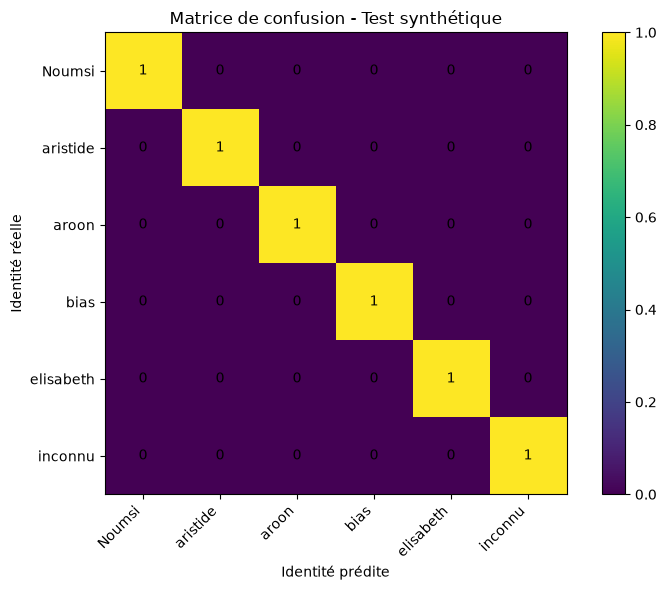

In [ ]:
# ============================================================
# ÉTAPE 10 : TEST DU CLASSIFICATEUR AVEC DES DONNÉES SYNTHÉTIQUES
# ============================================================

import sys
import numpy as np
import matplotlib.pyplot as plt

# Ajouter le dossier src au chemin de recherche de Python.
# Cela permet d'importer le module training.py.
sys.path.insert(0, str(RACINE_PROJET / "src"))

from training import FaceClassifier, evaluer_classificateur

# ------------------------------------------------------------
# 1. Créer des embeddings synthétiques pour cinq personnes.
# ------------------------------------------------------------
# Ces vecteurs servent uniquement à tester notre code.
# Ils ne proviennent pas de véritables visages.

embeddings_train = np.array([
    [1.0, 0.0, 0.0],   # Référence synthétique d'Aristide
    [0.0, 1.0, 0.0],   # Référence synthétique d'Aroon
    [0.0, 0.0, 1.0],   # Référence synthétique de Bias
    [-1.0, 0.0, 0.0],  # Référence synthétique d'Elisabeth
    [0.0, -1.0, 0.0]   # Référence synthétique de Noumsi
], dtype=np.float32)

etiquettes_train = np.array([
    "aristide",
    "aroon",
    "bias",
    "elisabeth",
    "noumsi"
])

# ------------------------------------------------------------
# 2. Construire le classificateur.
# ------------------------------------------------------------

classificateur = FaceClassifier(seuil=0.45)

# Construire la base de référence.
classificateur.entrainer(
    embeddings_train,
    etiquettes_train
)

print("Base de référence construite.")
print("Nombre d'identités :", len(
    classificateur.embeddings_par_personne
))

# ------------------------------------------------------------
# 3. Tester une personne connue.
# ------------------------------------------------------------

visage_test = np.array([0.98, 0.10, 0.0], dtype=np.float32)

identite, similarite = classificateur.predire(visage_test)

print("\nTest d'une personne connue")
print("Identité prédite :", identite)
print("Similarité :", round(similarite, 3))

# ------------------------------------------------------------
# 4. Tester un vecteur inconnu.
# ------------------------------------------------------------

visage_inconnu = np.array([0.0, 0.0, -1.0], dtype=np.float32)

identite, similarite = classificateur.predire(visage_inconnu)

print("\nTest d'une personne inconnue")
print("Identité prédite :", identite)
print("Similarité :", round(similarite, 3))

# ------------------------------------------------------------
# 5. Évaluer le classificateur sur des données synthétiques.
# ------------------------------------------------------------

embeddings_test = np.array([
    [0.99, 0.05, 0.0],   # Aristide
    [0.05, 0.99, 0.0],   # Aroon
    [0.0, 0.05, 0.99],   # Bias
    [-0.99, 0.05, 0.0],  # Elisabeth
    [0.0, -0.99, 0.05],  # Noumsi
    [0.0, 0.0, -1.0]     # Inconnu
], dtype=np.float32)

etiquettes_test = np.array([
    "aristide",
    "aroon",
    "bias",
    "elisabeth",
    "noumsi",
    "inconnu"
])

resultats = evaluer_classificateur(
    classificateur,
    embeddings_test,
    etiquettes_test
)

print("\nAccuracy synthétique :",
      round(resultats["accuracy"] * 100, 2), "%")

print("\nRapport de classification :")
print(resultats["rapport"])

# ------------------------------------------------------------
# 6. Afficher la matrice de confusion.
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.imshow(
    resultats["matrice_confusion"],
    interpolation="nearest"
)

plt.title("Matrice de confusion - Test synthétique")
plt.colorbar()

positions = np.arange(len(resultats["etiquettes"]))

plt.xticks(
    positions,
    resultats["etiquettes"],
    rotation=45,
    ha="right"
)

plt.yticks(
    positions,
    resultats["etiquettes"]
)

plt.xlabel("Identité prédite")
plt.ylabel("Identité réelle")

# Afficher les valeurs dans les cellules de la matrice.
for ligne in range(len(positions)):
    for colonne in range(len(positions)):
        valeur = resultats["matrice_confusion"][ligne, colonne]

        plt.text(
            colonne,
            ligne,
            str(valeur),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

# Extensions des fichiers image acceptés
EXTENSIONS_IMAGES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Personnes connues dans notre projet
PERSONNES = [
    "aristide",
    "aroon",
    "bias",
    "elisabeth",
    "noumssi"
]

# Fonction qui compte les images d'un dossier
def compter_images(dossier):
    dossier = Path(dossier)

    # Si le dossier n'existe pas, il contient zéro image
    if not dossier.exists():
        return 0

    # Compter les fichiers ayant une extension autorisée
    return sum(
        1
        for fichier in dossier.iterdir()
        if fichier.is_file()
        and fichier.suffix.lower() in EXTENSIONS_IMAGES
    )

# Vérifier les images destinées à l'entraînement
print("=== IMAGES D'ENTRAÎNEMENT ===")

for personne in PERSONNES:
    dossier = DOSSIER_TRAIN / personne
    nombre = compter_images(dossier)

    print(f"{personne} : {nombre} image(s)")

# Vérifier les images destinées aux tests
print("\n=== IMAGES DE TEST ===")

for personne in PERSONNES:
    dossier = DOSSIER_TEST / personne
    nombre = compter_images(dossier)

    print(f"{personne} : {nombre} image(s)")

# Vérifier les personnes inconnues
dossier_inconnu = DOSSIER_TEST / "inconnu"
nombre_inconnu = compter_images(dossier_inconnu)

print(f"\nPersonnes inconnues : {nombre_inconnu} image(s)")

=== IMAGES D'ENTRAÎNEMENT ===
aristide : 0 image(s)
aroon : 0 image(s)
bias : 0 image(s)
elisabeth : 0 image(s)
Noumssi : 0 image(s)

=== IMAGES DE TEST ===
aristide : 0 image(s)
aroon : 0 image(s)
bias : 0 image(s)
elisabeth : 0 image(s)
Noumssi : 0 image(s)

Personnes inconnues : 0 image(s)


In [4]:
# ============================================================
# TEST AUTOMATIQUE DU CLASSIFICATEUR AVEC DES DONNÉES FICTIVES
# ============================================================

import sys
from pathlib import Path
import numpy as np

# Ajouter le dossier src au chemin de recherche de Python
RACINE_PROJET = Path.cwd()

if not (RACINE_PROJET / "src").exists():
    RACINE_PROJET = RACINE_PROJET.parent

sys.path.insert(0, str(RACINE_PROJET / "src"))

from training import FaceClassifier

# Créer des empreintes fictives de dimension 128
# Les deux premières représentent la même identité.
# Les deux suivantes représentent une autre identité.
empreintes = np.zeros((4, 128), dtype=np.float32)

empreintes[0, 0] = 1.0
empreintes[1, 0] = 0.99
empreintes[1, 1] = 0.01

empreintes[2, 1] = 1.0
empreintes[3, 1] = 0.99
empreintes[3, 2] = 0.01

etiquettes = np.array([
    "personne_A",
    "personne_A",
    "personne_B",
    "personne_B"
])

# Entraîner le classificateur sur les données fictives
classificateur = FaceClassifier(seuil=0.365)
classificateur.entrainer(empreintes, etiquettes)

# Tester la reconnaissance de deux identités connues
prediction_A = classificateur.predire(empreintes[0])
prediction_B = classificateur.predire(empreintes[2])

# Créer une empreinte fictive très différente des deux identités
empreinte_inconnue = np.zeros(128, dtype=np.float32)
empreinte_inconnue[2] = 1.0

prediction_inconnue = classificateur.predire(empreinte_inconnue)

# Afficher les résultats
print("Résultat pour la personne A :", prediction_A)
print("Résultat pour la personne B :", prediction_B)
print("Résultat pour une personne inconnue :", prediction_inconnue)

# Vérifier uniquement le nom prédit, sans comparer le score
assert prediction_A[0] == "personne_A", "Échec de la reconnaissance de A."
assert prediction_B[0] == "personne_B", "Échec de la reconnaissance de B."
assert prediction_inconnue[0] == "UNKNOWN", "L'inconnu n'a pas été rejeté."

# Afficher le résultat final des tests
print("\nTous les tests du classificateur ont réussi !")




Résultat pour la personne A : ('personne_A', 0.9999874234199524)
Résultat pour la personne B : ('personne_B', 0.9999874234199524)
Résultat pour une personne inconnue : ('UNKNOWN', 0.005025062244385481)

Tous les tests du classificateur ont réussi !


In [5]:
# ============================================================
# TEST DE LA MATRICE DE CONFUSION
# ============================================================

from training import evaluer_classificateur

# Préparer des empreintes fictives pour l'évaluation
# Deux exemples de la personne A
# Deux exemples de la personne B
# Deux exemples représentant des personnes inconnues

empreintes_test = np.zeros((6, 128), dtype=np.float32)

empreintes_test[0, 0] = 1.0
empreintes_test[1, 0] = 0.98
empreintes_test[1, 1] = 0.02

empreintes_test[2, 1] = 1.0
empreintes_test[3, 1] = 0.98
empreintes_test[3, 2] = 0.02

empreintes_test[4, 2] = 1.0
empreintes_test[5, 3] = 1.0

# Définir les véritables identités des exemples
etiquettes_reelles = np.array([
    "personne_A",
    "personne_A",
    "personne_B",
    "personne_B",
    "UNKNOWN",
    "UNKNOWN"
])

# Évaluer le classificateur déjà entraîné
resultats = evaluer_classificateur(
    classificateur,
    empreintes_test,
    etiquettes_reelles
)

# Afficher les résultats de l'évaluation
print("\nPrécision globale :", resultats["accuracy"])
print("\nIdentités évaluées :", resultats["etiquettes"])
print("\nMatrice de confusion :")
print(resultats["matrice_confusion"])

print("\nRapport de classification :")
print(resultats["rapport"])



Précision globale : 1.0

Identités évaluées : ['UNKNOWN', 'personne_A', 'personne_B']

Matrice de confusion :
[[2 0 0]
 [0 2 0]
 [0 0 2]]

Rapport de classification :
              precision    recall  f1-score   support

     UNKNOWN       1.00      1.00      1.00         2
  personne_A       1.00      1.00      1.00         2
  personne_B       1.00      1.00      1.00         2

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



In [6]:
# ============================================================
# VÉRIFICATION DU PIPELINE D'ENTRAÎNEMENT
# ============================================================

import sys
from pathlib import Path

# Déterminer la racine du projet
RACINE_PROJET = Path.cwd()

if not (RACINE_PROJET / "src").exists():
    RACINE_PROJET = RACINE_PROJET.parent

# Ajouter src au chemin de recherche de Python
sys.path.insert(0, str(RACINE_PROJET / "src"))

# Importer les fonctions du pipeline
from pipeline import extraire_donnees, entrainer_modele, evaluer_modele

# Vérifier le dossier d'entraînement
DOSSIER_TRAIN = RACINE_PROJET / "data" / "split" / "train"

# Compter les fichiers image disponibles
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

nombre_images = sum(
    1
    for fichier in DOSSIER_TRAIN.rglob("*")
    if fichier.is_file() and fichier.suffix.lower() in extensions
)

print("Racine du projet :", RACINE_PROJET)
print("Dossier d'entraînement :", DOSSIER_TRAIN)
print("Nombre d'images d'entraînement :", nombre_images)

# Vérifier que le pipeline peut être importé
print("\nPipeline importé correctement.")


Racine du projet : c:\Users\dell\Projet1_reco_faciale
Dossier d'entraînement : c:\Users\dell\Projet1_reco_faciale\data\split\train
Nombre d'images d'entraînement : 0

Pipeline importé correctement.


In [7]:
# ============================================================
# TEST DE L'EXTRACTION DES DONNÉES
# ============================================================

# Importer la fonction du pipeline
from pipeline import extraire_donnees

# Extraire les données du dossier d'entraînement
empreintes, etiquettes = extraire_donnees(DOSSIER_TRAIN)

# Afficher les dimensions des données obtenues
print("Forme des empreintes :", empreintes.shape)
print("Nombre d'étiquettes :", len(etiquettes))
print("Identités trouvées :", sorted(set(etiquettes)))

# Vérifier le comportement lorsque le dossier est vide
if len(empreintes) == 0:
    print("\nAucune empreinte extraite : les données sont toujours absentes.")
else:
    print("\nExtraction terminée.")


Traitement de l'identité : aristide

Traitement de l'identité : aroon

Traitement de l'identité : bias

Traitement de l'identité : elisabeth

Traitement de l'identité : Noumssi
Forme des empreintes : (0, 128)
Nombre d'étiquettes : 0
Identités trouvées : []

Aucune empreinte extraite : les données sont toujours absentes.


In [11]:
# ============================================================
# TEST DE LA SAUVEGARDE DES RÉSULTATS FICTIFS
# ============================================================

from pipeline import sauvegarder_resultats
from pathlib import Path
import json

# Définir le chemin de sauvegarde dans le dossier results
chemin_test = RACINE_PROJET / "results" / "evaluation_test_fictif.json"

# Enregistrer les résultats fictifs calculés précédemment
fichier_cree = sauvegarder_resultats(resultats, chemin_test)

# Vérifier que le fichier existe
assert fichier_cree.exists(), "Le fichier JSON n'a pas été créé."

# Relire le fichier pour vérifier son contenu
with open(fichier_cree, "r", encoding="utf-8") as fichier:
    donnees_sauvegardees = json.load(fichier)

# Afficher les informations enregistrées
print("\nPrécision sauvegardée :", donnees_sauvegardees["accuracy"])
print("Identités évaluées :", donnees_sauvegardees["etiquettes"])
print("Matrice de confusion :")
print(donnees_sauvegardees["matrice_confusion"])

print("\nTest de sauvegarde réussi !")

Résultats sauvegardés dans : c:\Users\dell\Projet1_reco_faciale\results\evaluation_test_fictif.json

Précision sauvegardée : 1.0
Identités évaluées : ['UNKNOWN', 'personne_A', 'personne_B']
Matrice de confusion :
[[2, 0, 0], [0, 2, 0], [0, 0, 2]]

Test de sauvegarde réussi !


In [12]:
# Recharger le module pipeline après sa modification
import importlib
import pipeline

importlib.reload(pipeline)

# Importer la fonction après le rechargement
from pipeline import sauvegarder_resultats

print("Fonction de sauvegarde chargée avec succès !")

Fonction de sauvegarde chargée avec succès !


In [13]:
# Recharger le module après sa modification
import importlib
import pipeline

importlib.reload(pipeline)

# Importer la nouvelle fonction
from pipeline import afficher_matrice_confusion

print("Fonction de visualisation importée avec succès !")

Fonction de visualisation importée avec succès !


Matrice enregistrée dans : C:\Users\dell\Projet1_reco_faciale\results\matrice_confusion.png


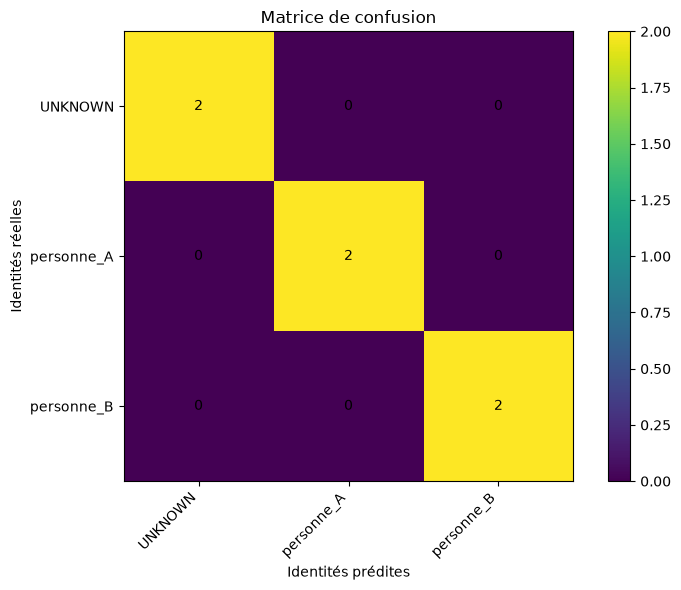

In [14]:
# ============================================================
# AFFICHAGE DE LA MATRICE DE CONFUSION
# ============================================================

# Importer la fonction de visualisation
from pipeline import afficher_matrice_confusion

# Afficher la matrice calculée précédemment
afficher_matrice_confusion(resultats, sauvegarder=True)

